# 4.0 - Inferencia

Genera las predicciones de `SalePrice` para el set de test de Kaggle a partir de los **datos crudos** (`data/raw/test.csv`), usando el modelo con alias **`@champion`** del Model Registry de MLflow (`house_pricing`): un pipeline completo con selección de features, feature engineering, el modelo y la reversión a dólares. El resultado se guarda en formato de envío a Kaggle en `data/processed/predicciones_test.csv` y la ejecución queda registrada en el experimento de inferencia de MLflow.

## Configuración

Importa las librerías, define las rutas del proyecto y conecta MLflow a la base SQLite local (`mlflow.db`) con la configuración de `pipeline_config.yaml`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
from mlflow import MlflowClient
import pandas as pd
import yaml
from matplotlib.ticker import FuncFormatter

PROJ_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJ_ROOT / "data" / "processed"

with open(PROJ_ROOT / "pipeline_config.yaml") as f:
    MLFLOW_CONFIG = yaml.safe_load(f)["MLFLOW"]

MODELO_REGISTRADO = MLFLOW_CONFIG["MODELO_REGISTRADO"]
ALIAS = "champion"

mlflow.set_tracking_uri(f"sqlite:///{PROJ_ROOT / MLFLOW_CONFIG['TRACKING_DB']}")
cliente_mlflow = MlflowClient()

## Pipeline de inferencia (champion del Model Registry)

Busca la versión del modelo `house_pricing` que tiene el alias `@champion`, muestra su información (versión, etiquetas y métricas) y la carga con `mlflow.sklearn.load_model`. Como se carga por alias, si en otra corrida del notebook 3.0 cambia el champion, la inferencia usa el nuevo sin modificar este código.

Es un único objeto que contiene todo el flujo, en orden:

1. `seleccion_features`: deja solo las columnas de `MODEL_FEATURES`.
2. `fe`: imputación, codificación, capping, Yeo-Johnson y escalado, con los parámetros aprendidos en entrenamiento.
3. `modelo`: el modelo champion.
4. Reversión con `expm1`: la salida queda en dólares.

In [2]:
version_champion = cliente_mlflow.get_model_version_by_alias(MODELO_REGISTRADO, ALIAS)
modelo_uri = f"models:/{MODELO_REGISTRADO}@{ALIAS}"

display(pd.Series({
    "modelo_uri": modelo_uri,
    "version": version_champion.version,
    "run_id": version_champion.run_id,
    "descripcion": version_champion.description,
    **version_champion.tags,
}, name="champion").to_frame())

pipeline_inferencia = mlflow.sklearn.load_model(modelo_uri)
pipeline_inferencia

,champion
modelo_uri,models:/house_pricing@champion
version,1
run_id,6f585fb65d5a443b95a55322b376fc01
descripcion,"Gradient Boosting (champion): RMSE valid $22,0..."
tipo_modelo,gradient_boosting
familia,ensamble
modelo,Gradient Boosting
alias_inicial,champion
posicion_torneo,1
rmse_valid,22065.89


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...sample=0.8))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0",list,"['MS...ss', 'MS...ng', 'Lo...ge', 'LotArea', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,79
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...sample=0.8))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('seleccion_features', ...), ('fe', ...), ...]"


## Carga de los datos crudos de test

Lee `test.csv` sin ninguna transformación, con `Id` como índice. El pipeline espera exactamente las mismas columnas crudas que `train.csv` (sin `SalePrice`).

In [3]:
test = pd.read_csv(RAW_DATA_DIR / "test.csv", index_col="Id")
print(f"test: {test.shape}")
test.head()

test: (1459, 79)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
Id,,,,,,,,,,,,,,,,,,,,,
1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


## Predicción

Aplica el pipeline completo a los datos crudos y obtiene el precio estimado en dólares para cada casa.

In [4]:
predicciones = pd.Series(pipeline_inferencia.predict(test), index=test.index, name="SalePrice")
predicciones.describe()

count      1459.000000
mean     178178.559263
std       79553.735900
min       44414.587329
25%      127726.674323
50%      156568.603154
75%      206766.713998
max      726594.290565
Name: SalePrice, dtype: float64

## Validación de las predicciones

Verifica que haya una predicción por cada casa de test, sin faltantes y con precios positivos, y que los `Id` coincidan con `sample_submission.csv`. El histograma compara la distribución de las predicciones con la de los precios reales de train: deberían tener una forma parecida.

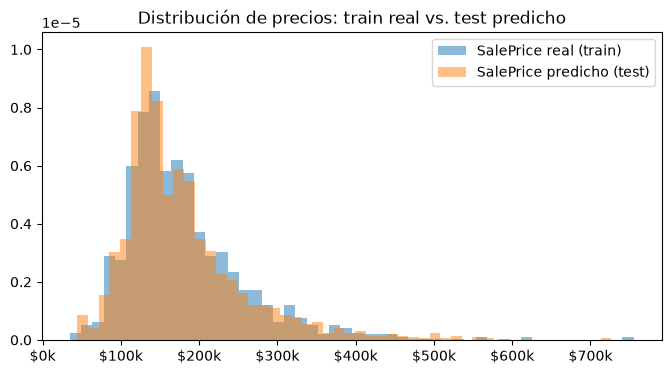

In [5]:
sample_submission = pd.read_csv(RAW_DATA_DIR / "sample_submission.csv")

assert len(predicciones) == len(test)
assert predicciones.notna().all()
assert (predicciones > 0).all()
assert (predicciones.index == sample_submission["Id"]).all()

precios_train = pd.read_csv(RAW_DATA_DIR / "train.csv", usecols=["SalePrice"])["SalePrice"]

fig_distribucion, ax = plt.subplots(figsize=(8, 4))
ax.hist(precios_train, bins=50, alpha=0.5, density=True, label="SalePrice real (train)")
ax.hist(predicciones, bins=50, alpha=0.5, density=True, label="SalePrice predicho (test)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x / 1000:,.0f}k"))
ax.set_title("Distribución de precios: train real vs. test predicho")
ax.legend()
plt.show()

## Guardado de las predicciones

Guarda las predicciones en `data/processed/predicciones_test.csv` con las columnas `Id` y `SalePrice`, el mismo formato de `sample_submission.csv`, listo para enviar a Kaggle.

In [6]:
ruta_predicciones = PROCESSED_DATA_DIR / "predicciones_test.csv"
predicciones.reset_index().to_csv(ruta_predicciones, index=False)

print(f"Guardado en: {ruta_predicciones.relative_to(PROJ_ROOT)}")
pd.read_csv(ruta_predicciones).head()

Guardado en: data/processed/predicciones_test.csv


,Id,SalePrice
0,1461,122554.271445
1,1462,148373.249832
2,1463,179942.901003
3,1464,182802.005179
4,1465,195840.884148


## Registro de la inferencia en MLflow

Registra la ejecución en el experimento de inferencia (si no existe, lo crea con sus artefactos en `mlruns/`):

- **Parámetros:** el modelo usado (URI, versión, tipo y run de origen).
- **Métricas:** número de predicciones y estadísticos de los precios predichos (media, mediana, mínimo y máximo).
- **Artefactos:** el CSV de predicciones y el histograma de distribución.

In [7]:
experimento_inferencia = MLFLOW_CONFIG["EXPERIMENTO_INFERENCIA"]
if mlflow.get_experiment_by_name(experimento_inferencia) is None:
    mlflow.create_experiment(
        experimento_inferencia, artifact_location=(PROJ_ROOT / MLFLOW_CONFIG["ARTIFACTS_DIR"]).as_uri()
    )
mlflow.set_experiment(experimento_inferencia)

with mlflow.start_run(run_name="inferencia_test") as run_inferencia:
    mlflow.set_tags({"alias": ALIAS, **version_champion.tags})
    mlflow.log_params({
        "modelo_uri": modelo_uri,
        "version_modelo": version_champion.version,
        "run_id_modelo": version_champion.run_id,
        "datos_entrada": "data/raw/test.csv",
    })
    mlflow.log_metrics({
        "n_predicciones": len(predicciones),
        "precio_medio": predicciones.mean(),
        "precio_mediano": predicciones.median(),
        "precio_minimo": predicciones.min(),
        "precio_maximo": predicciones.max(),
    })
    mlflow.log_artifact(str(ruta_predicciones))
    mlflow.log_figure(fig_distribucion, "distribucion_predicciones.png")

print(f"Run de inferencia: {run_inferencia.info.run_id}")

Run de inferencia: db130be97bf2497c9ae44f61b14e9933
